In [12]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

LOAD THE RFM SAVED DATA

In [13]:
customer_rfm = pd.read_csv("../data/processed/customer_rfm.csv")
customer_rfm.head()

,user_id,total_orders,total_spend,total_quantity,average_order_value,first_order_date,last_order_date,age,gender,marital_status,occupation,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_total,rfm_segment
0,1,2,1672,5,836.000000,2017-12-12,2018-11-14,20,Female,Single,Student,590,2,1672,2,2,3,223,7,Potential Loyalists
1,2,3,4061,7,1353.666667,2018-02-13,2018-08-03,24,Female,Single,Student,693,3,4061,1,3,4,134,8,At Risk - High Value
2,3,1,21542,500,21542.000000,2019-05-15,2019-05-15,22,Male,Single,Student,408,1,21542,3,1,5,315,9,Potential Loyalists
3,4,1,102,1,102.000000,2019-02-06,2019-02-06,22,Female,Single,Student,506,1,102,2,1,1,211,4,Lost / Low Value
4,5,2,52047,50,26023.500000,2018-03-02,2018-07-25,22,Male,Single,Student,702,2,52047,1,2,5,125,8,At Risk - High Value


FEATURES FOR SELECTING

In [14]:
X = customer_rfm[["recency", "frequency", "monetary"]].copy()

X["frequency"] = np.log1p(X["frequency"])
X["monetary"] = np.log1p(X["monetary"])

SCALE THE DATA

In [15]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

TO FIND THE NUMBER OF CLUSTERS

In [16]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

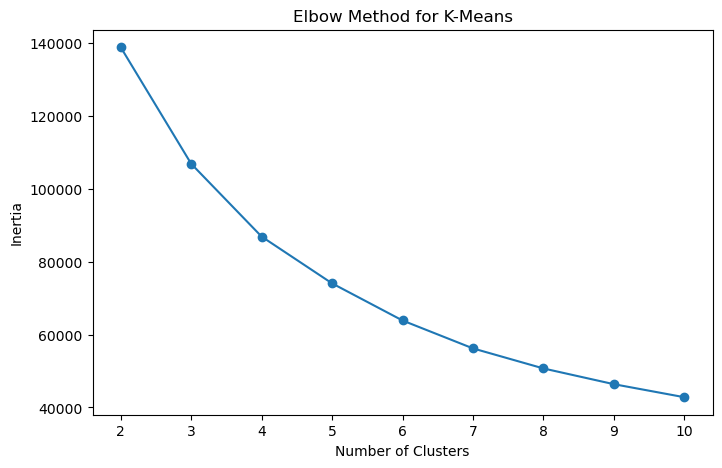

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11),inertia,marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")

plt.show()

APPLYING K_MEANS BECAUSE THE THE CURVE FLATTENS AT 4

In [18]:
kmeans = KMeans(n_clusters=4,random_state=42,n_init=10)

customer_rfm["cluster"] = kmeans.fit_predict(X_scaled)

CHECKING CLUSTER SIZES

In [19]:
customer_rfm["cluster"].value_counts().sort_index()

cluster
0    15135
1    17927
2    23595
3    20889
Name: count, dtype: int64

In [20]:
cluster_summary = (customer_rfm.groupby("cluster").agg(customers=("user_id", "count"),avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),avg_monetary=("monetary", "mean")).reset_index())

cluster_summary

,cluster,customers,avg_recency,avg_frequency,avg_monetary
0,0,15135,601.595309,1.613148,24505.045590
1,1,17927,727.750265,1.153623,543.374184
2,2,23595,220.364781,3.091206,23533.455605
3,3,20889,234.859591,1.459859,1379.296376


In [21]:
customer_rfm.to_csv("../outputs/tables/customer_segments.csv",index=False)

In [22]:
cluster_summary.to_csv("../outputs/tables/cluster_summary.csv",index=False)